# Frozen external references and deployment
Evaluate DDColor, CT2, BigColor, SwinIR and Real-ESRGAN on the same observations as the local models.
[Source pins, checkpoint hashes and licenses](../assets/external_restoration_manifest.json).
External sources and weights are not redistributed by this repository.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display
def preview(path):
    # Compressed display preview; full-resolution scientific figures remain in assets.
    with PILImage.open(path) as picture:
        picture.thumbnail((760,760))
        buffer = BytesIO()
        picture.convert('RGB').save(buffer,format='JPEG',quality=90)
    display(NotebookImage(data=buffer.getvalue()))

In [2]:
manifest = json.loads((root/'assets/external_restoration_manifest.json').read_text())
pd.DataFrame(manifest['sources']).T

,repository,revision,license
CT2,https://github.com/shuchenweng/CT2,cd40f5a0cee23365b831f25ab5d659674936018b,CC BY-NC 4.0
BigColor,https://github.com/KIMGEONUNG/BigColor,5b7687fbedd9af22fef02a82102c6d7708ab1217,MIT
SwinIR,https://github.com/JingyunLiang/SwinIR,6545850fbf8df298df73d81f3e8cba638787c8bd,Apache-2.0
BasicSR,https://github.com/XPixelGroup/BasicSR,8d56e3a045f9fb3e1d8872f92ee4a4f07f886b0a,Apache-2.0


In [3]:
rows = []
for study in ['external_ddcolor','external_ct2','external_bigcolor','external_swinir','external_realesrgan']:
    m = evidence(study)
    rows.extend({'method':r['method'],'sample':r['sample'],
                 'psnr':r['psnr']['mean'],'lpips':r['lpips']['mean'],
                 'consistency':r['data_consistency_l1']['mean']} for r in m['rows'])
pd.DataFrame(rows)

,method,sample,psnr,lpips,consistency
0,ddcolor,0,23.149220,0.140595,0.000087
1,ct2,0,22.980606,0.155214,0.000230
2,bigcolor,0,21.225463,0.178623,0.000404
3,bigcolor,1,21.211782,0.178770,0.000421
4,bigcolor,2,21.188142,0.179100,0.000409
5,bigcolor,3,21.163169,0.179578,0.000419
6,swinir,0,27.132186,0.223292,0.001921
7,realesrgan,0,23.026612,0.206361,0.022798


## Exposure and adapters
BigColor uses the released encoder/generator and EMA with a fixed ResNet50 class
selector, differing from its default EfficientNet-L2. CT2 processes 256px lightness
and receives zero chroma in its diagnostic target argument. DDColor processes
512px internally, without extra observed detail. SwinIR receives actual LR rather
than a second downsampling of the enlarged image. Real-ESRGAN training uses blind degradations, differing from this controlled bicubic test. CT2 has a noncommercial license.

In [4]:
weights = pd.DataFrame(manifest['weights']).T
assert all(len(value)==64 for value in weights.sha256)
weights[['sha256','bytes']]

,sha256,bytes
CT2/release.rar,08e2ad96667a6132e2563a99b7753b338bff6a7da16d36...,3437688179
BigColor/ckpts/bigcolor/EG_011.ckpt,55d759b259a6cb55d5246a2a9e33831ad34b700d1d24b8...,421038721
BigColor/ckpts/bigcolor/EG_EMA_011.ckpt,13d0421457c30b78f391ba293c99b7a22e6233add7b98d...,841647801
BigColor/ckpts/bigcolor/args.pkl,523e05d97c8eeb02fd1755b51703e2cc4e03d01dd5da3c...,3917
BigColor/pretrained/config.pickle,e860eb9f702ba7a7ddb7446350199fd6eee68e4e0b97aa...,1899
CT2/checkpoint.pth,48a4f53900d20c0f86d52679ba9d8fc25f1087b78c0475...,3700033417
SwinIR/001_classicalSR_DF2K_s64w8_SwinIR-M_x4.pth,4e78e33f22c1aa8a773db0cf4a7381bae97c2362c717f1...,67869037
SwinIR/005_colorDN_DFWB_s128w8_SwinIR-M_noise25.pth,39e264322ba762682de5acee4705aaeda7077b947204b9...,122905743
BasicSR/weights/RealESRGAN_x4plus.pth,4fa0d38905f75ac06eb49a7951b426670021be3018265f...,67040989
torch/hub/checkpoints/alexnet-owt-7be5be79.pth,7be5be791159472b1fbf3c69796f7cb30dca7ad8466c2d...,244408911


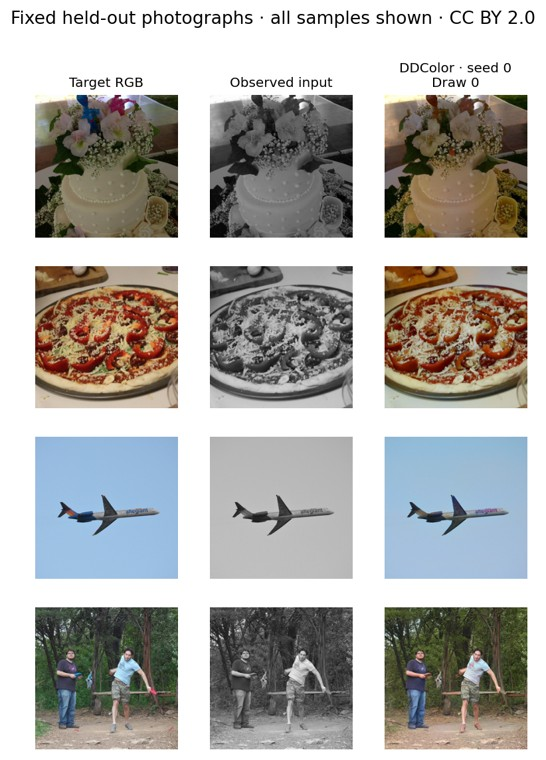

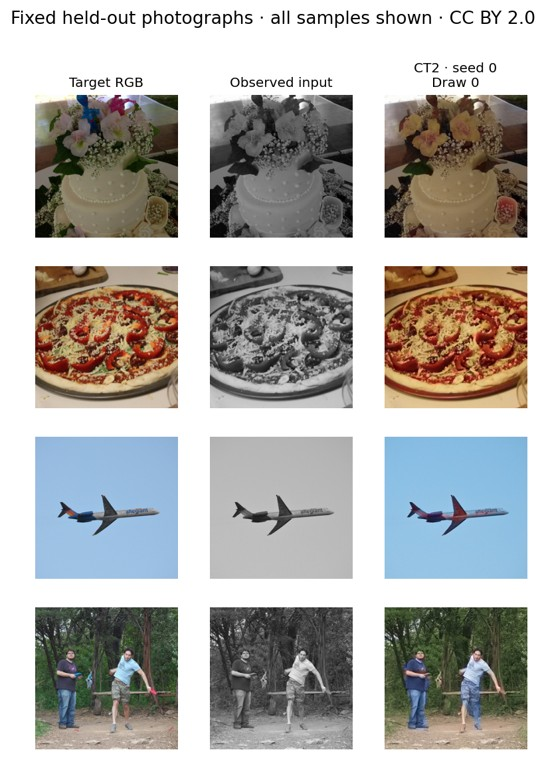

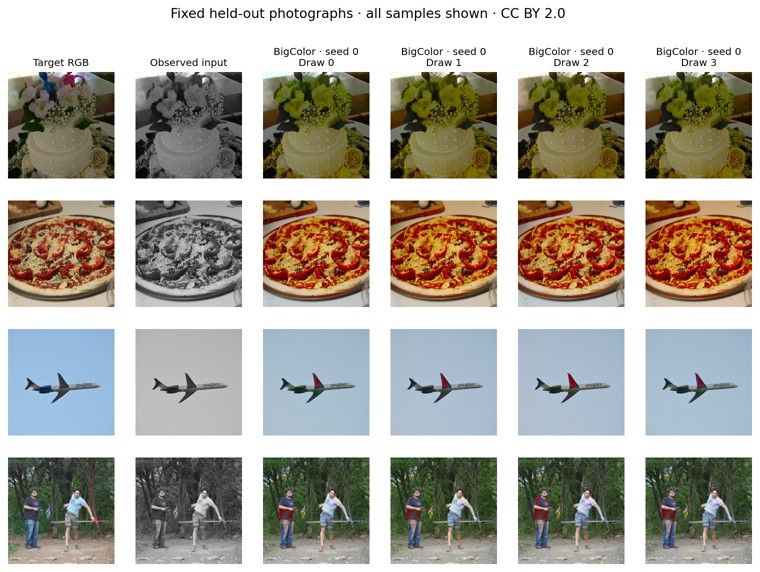

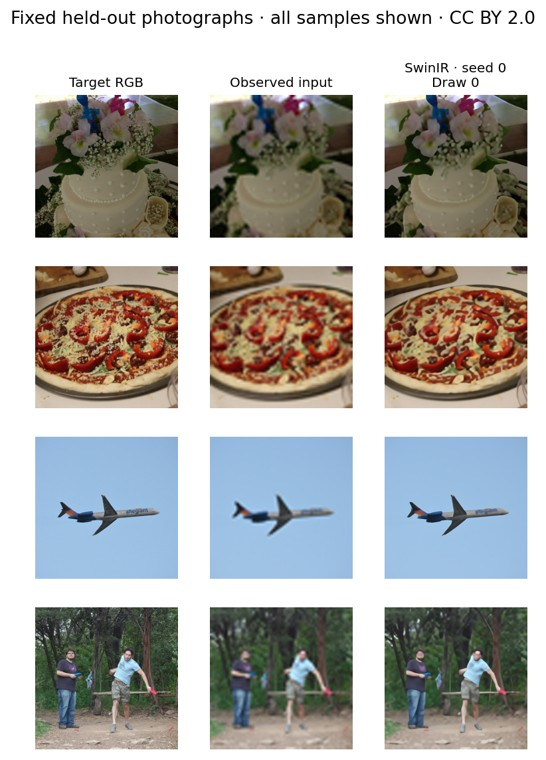

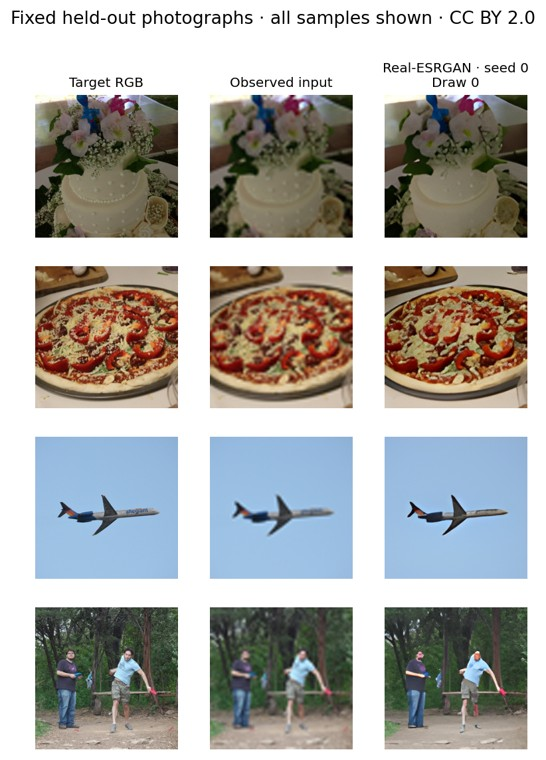

In [5]:
from IPython.display import Image,display
for method in ['ddcolor','ct2','bigcolor','swinir','realesrgan']:
    paths = sorted(root.glob(f'assets/external_{method}_*_gallery.png'))
    assert paths
    for path in paths:
        preview(path)

## Worked answer
Does a frozen model beating a local one establish a superior algorithm? This is a
practical pipeline comparison. Training data, architecture and compute all differ,
and external-data overlap has not been audited. State the adapter and exposure,
report measured values rather than quoting the paper's different benchmark numbers,
and provide a direct inference command with explicit preprocessing.